In [1]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import openpyxl

In [1]:
from rugbypy.match import *
from rugbypy.competition import *
from rugbypy.team import *
from rugbypy.venue import *
from rugbypy.player import *

In [9]:
pd.options.mode.chained_assignment = None

In [4]:
## Reading Data

test_matches = pd.read_excel("detailed_test_matches.xlsx") ## Description of match contexts and the final score of each match
match_stats = pd.read_excel("aggregated_stats.xlsx") ## Match stats collected using player data instead of team data
test_nations = pd.read_excel("test_nations.xlsx") ## List of all Tier 1 Test Nations
team_stats = pd.read_excel("team_stats.xlsx") ## Match stats by team
venues = fetch_all_venues() ## All venues in the database

Fetching all venues...


In [8]:
## Full Data Wrangling Process:

test_matches = test_matches[test_matches['home_team'].isin(test_nations['team_name']) &
                            test_matches['away_team'].isin(test_nations['team_name'])]

test_matches = test_matches[test_matches['home_team'] != "Fiji"]

## Only selecting the necessary variables for outcome
test_match_results = test_matches[['match_id', 'date', 'season', 'competition_id', 'competition', 'venue_id', 'venue', 
                                    'home_team', 'home_team_id', 'away_team', 'away_team_id', 'home_score', 'away_score']]

## Creating a winner variable
test_match_results['winner'] = np.where(test_match_results['home_score'] == test_match_results['away_score'],
                                "Draw", np.where(test_match_results['home_score'] > test_match_results['away_score'], 
                                test_match_results['home_team'], test_match_results['away_team']))

## Creating a new variable classify if the home team won or not
test_match_results['home_team_win'] = np.where(test_match_results['winner'] == test_match_results['home_team'], 1, 0)

## Designating all RWC matches as neutral matches outside of the matches that featured France (hosted the tournament)
test_match_results['neutral_match'] = np.where((test_match_results['competition'] == "Rugby World Cup") &
                                                (test_match_results['home_team'] != "France"),
                                                "neutral", "NA")

## test_match_results - information on all test matches including tests where there is no clear home team (neutral match)

home_away_tests = test_match_results[test_match_results['neutral_match'] != "neutral"]

## Removal of New Zealand v. South Africa @ Twickenham (Neutral site RWC Prep Match)
home_away_tests = home_away_tests[~home_away_tests['match_id'].isin(['db7135be'])]

## Only included venues that have hosted a test match

test_venues = venues[venues['venue_id'].isin(test_match_results['venue_id'])]

## Validation of the venues list; removed Wembley Stadium and Soldier Field

test_venues = test_venues[~test_venues['venue_name'].isin(['Wembley Stadium', 'Soldier Field'])] 

## Only including match stats between Tier 1 nations

match_stats = match_stats[match_stats['team'].isin(test_nations['team_name'])]

match_stats = match_stats.rename(columns = {"team": "team_name"})

match_stats = match_stats[match_stats['turnovers_lost'] < 30] ## Some matches had teams who committed 100+ turnovers 
match_stats = pd.merge(test_nations, match_stats, how = 'inner', on = 'team_name')

team_stats = team_stats[['team_id', 'team', 'game_date', 'team_vs', 'team_vs_id', 'match_id', '22m_entries', '22m_conversion',
                        'post_contact_metres', 'ruck_speed_0_3_pct', 'ruck_speed_3_6_pct', 'ruck_speed_6_plus_pct',
                        'possession', 'territory', 'scrums_total', 'mauls_total', 'rucks_total']] 
## All stats not collected using player data


team_stats = team_stats.rename(columns={"team": "team_name"}) # renamed for the purpose of joining

<positron-console-cell-8>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-8>:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<positron-console-cell-8>:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [10]:
## Condensing the model set to mirror the dataset used for the model

potential_model_set = pd.merge(team_stats, match_stats, how="left", on = ['team_id', 'team_name', 'match_id'])

## Home/Away Designation

## Intended columns to drop; all associated with each team and associated score. game_date is a redundant column. 

drop_cols = ['team_name', 'team_vs', 'team_vs_id', 'game_date', 'score', 'team_vs_score']

potential_model_set.drop(columns = [c for c in drop_cols if c in potential_model_set.columns])

stat_cols = [c for c in potential_model_set.columns if c not in ('team_id', 'match_id')]

## Creates a new data frame that adds the home designation for the statistics associated with the home team

home_team_stats = potential_model_set.rename(columns={
    'team_id': 'home_team_id',
    **{c: f'home_{c}' for c in stat_cols}
})

## Creates a new data frame that adds the away designation for the statistics associated with the away team

away_team_stats = potential_model_set.rename(columns={
    'team_id': 'away_team_id',
    **{c: f'away_{c}' for c in stat_cols}
})

## Joins both data sets

potential_model_set = pd.merge(test_match_results, home_team_stats, on = ['match_id', 'home_team_id'], how = 'left')

potential_model_set = potential_model_set.merge(away_team_stats, on = ['match_id', 'away_team_id'], how = 'left')

potential_model_set = potential_model_set[potential_model_set['neutral_match'] != "neutral"]

potential_model_set = potential_model_set.drop(columns=['neutral_match', 'home_game_date', 'away_game_date'])


model_set = potential_model_set[['match_id', 'date', 'season', 'competition_id', 'competition','venue_id', 'venue', 
                                        'home_team_id', 'home_team', 'away_team_id', 'away_team', 'home_score', 'away_score',
                                        'winner', 'home_team_win', 'home_carries', 'away_carries', 'home_line_breaks',
                                        'away_line_breaks', 'home_tackles_made', 'away_tackles_made', 'home_tackles_missed',
                                        'away_tackles_missed', 'home_kicks', 'away_kicks', 'home_metres_carried',
                                        'away_metres_carried', 'home_defenders_beaten', 'away_defenders_beaten',
                                        'home_yellow_cards', 'away_yellow_cards', 
                                        'home_red_cards', 'away_red_cards', 'home_tries', 'away_tries', 'home_penalties_conceded', 'away_penalties_conceded', 
                                         'home_penalty_goals', 'away_penalty_goals']]

model_set = model_set.dropna()


In [17]:
model_set['home_team_win'] = model_set['home_team_win'].astype('category')
garbage = ['b8980cf7',  'd661c5a6', 'de4008a7', '99ea4482', '1e174fdb']

model_set = model_set[~model_set['match_id'].isin(garbage)]


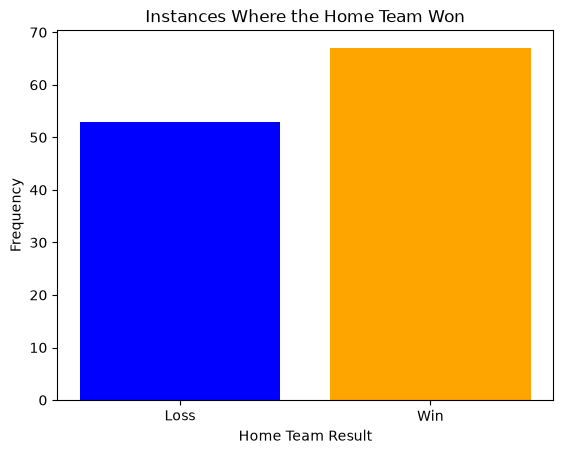

In [36]:
## EDA - Bar Chart: Number of Times the Home Team Won in the Dataset


home_wins = model_set['home_team_win'].value_counts()

plt.bar(home_wins.index, 
        home_wins.values,
        color = ['orange', 'blue']
)
plt.xticks([0, 1], ['Loss', 'Win'])
plt.xlabel("Home Team Result")
plt.ylabel("Frequency")
plt.title("Instances Where the Home Team Won")

plt.savefig(
    'win_counts.png',
    dpi = 300,
    bbox_inches = 'tight',
    transparent = False
)

plt.show()


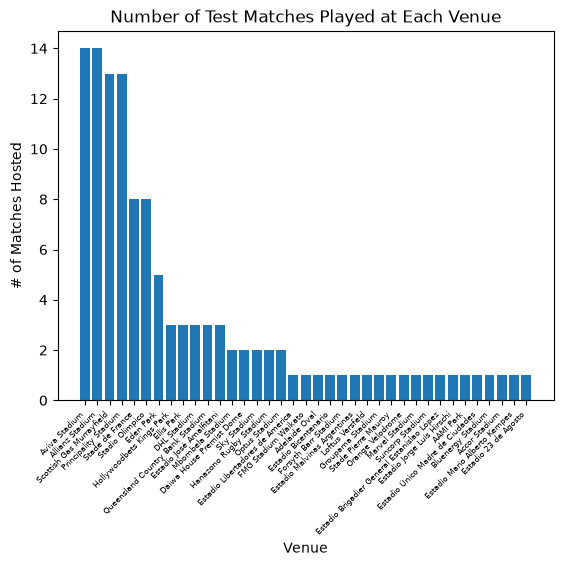

In [29]:
## EDA - Bar Chart Showing the Number of Times A Venue Hosted a Match

venue_counts = model_set['venue'].value_counts().sort_values(ascending=False)

plt.bar(
    venue_counts.index,
    venue_counts.values
)
plt.xticks(rotation=45, ha='right', fontsize = 6)
plt.xlabel('Venue')
plt.ylabel('# of Matches Hosted')
plt.title('Number of Test Matches Played at Each Venue')

plt.savefig(
    'venue_count.png',
    dpi=300,
    bbox_inches='tight',
    transparent=False
)

plt.show()
